# Molecular docking -- Lavandula_angustifolia vs ACE (1O86)



In [1]:
from pymol import cmd
import py3Dmol

from vina import Vina

from openbabel import pybel

from rdkit import Chem
from rdkit.Chem import AllChem, Draw

from meeko import MoleculePreparation

import MDAnalysis as mda
from MDAnalysis.coordinates import PDB

import prolif as plf
from prolif.plotting.network import LigNetwork


import sys, os
sys.path.insert(1, "/home/ali/medical plants/docking/Jupyter_Dock-main/utilities/")
from utils import fix_protein, getbox, generate_ledock_file, pdbqt_to_sdf, dok_to_sdf


import warnings
warnings.filterwarnings("ignore")
%config Completer.use_jedi = False

/home/ali/Downloads/or/envs/jupdock_clean/lib/python3.10/site-packages/MDAnalysis/topology/tables.py:52: DeprecationWarning: Deprecated in version 2.8.0
MDAnalysis.topology.tables has been moved to MDAnalysis.guesser.tables. This import point will be removed in MDAnalysis version 3.0.0
  warnings.warn(wmsg, category=DeprecationWarning)


It's a good idea to run the test protocols before attempting custom projects. Later, the user can specify the location of his/her project and save all of the files separately.

In [2]:
os.chdir('/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/')


## 1. Feching system and cleanup

Implementing Pymol is a simple way to download PDB structures. The user can launch this or any other Jupyter Dock's protocol by providing his or her own files.

In [3]:
cmd.fetch(code='1O86',type='pdb1')

# Keep the catalytic zinc WITH the protein (unlike HEM/NADP+ in other
# targets) -- ACE's zinc is directly coordinated by lisinopril's carboxylate
# group and is mechanistically central to inhibitor binding, not just a
# supporting cofactor.
cmd.select(name='Prot', selection='polymer.protein or (resn ZN and chain A)')
cmd.save(filename='1O86_clean.pdb', format='pdb', selection='Prot', state=1)

# Native ligand: lisinopril, PDB ligand code LPR, chain A only.
cmd.select(name='NativeLig', selection='resn LPR and chain A')
_natlig_model = cmd.get_model('NativeLig', state=1)
print("Native ligand (lisinopril) atom count:", len(_natlig_model.atom))
cmd.save(filename='1O86_native_lig.mol2', format='mol2', selection='NativeLig', state=1)
cmd.delete('all')


Native ligand (lisinopril) atom count: 29


## 2. Protein and ligand sanitization

### 2.1. Protein Sanitization

#### Method 1: LePro

The Lephar molecular docking suite includes a very powerful tool for automatically preparing proteins for molecular docking. As a result, for these protocols, it will be the preferred tool for protein preparation. The protein prepared by LePro can be used in AutoDock VIna and LeDock.

In [4]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" # Launch this cell to see parameters


************************************************************
*      LePro                                               *
*            Add hydrogen atoms to a protein &             *
*            write the input file for LeDock               *
*      Copyright (C) 2013-21 Hongtao Zhao, PhD             *
*      Email: htzhaovv@gmail.com                           *
************************************************************
----------Usage:                                                                       
          lepro [PDB file] [-rot || -metal || -p]                                        
          -rot  [[chain] resid] align principal axes of the binding site with Cartesian
          -metal keep ZN/MN/CA/MG                                                      
          -metal -p redistribute metal charge to protein                               



In [5]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" {'1O86_clean.pdb'}

os.rename('pro.pdb','1O86_clean_H.pdb')

# Note: lepro is built for standard amino-acid protein files and may not
# correctly handle a receptor file with a HETATM (the zinc ion) mixed in.
# If lepro drops or mishandles the zinc, check the output '1O86_clean_H.pdb'
# for a ZN record; if it's missing, use fix_protein() (Method 2 below)
# instead for this target, which is more likely to preserve HETATM entries.


#### Method 2: fix_protein (PDBFixer)

For proteins with missing amino acids or residues, or to ensure a more thorough sanitization of protein Jupyter Dock includes the _fix_protein()_ function, which employs PDBFixer to correct a wide range of common errors in protein pdb files. Furthermore, PDBFixer enables the assignment of pH-dependent protonation states to proteins.


>**Warning 1:**  It is possible to encounter problems with protein fixing when using **_fix_protein()_** and AutoDock Tools' **_prepare_receptor_** or when running LeDock. To resolve the issue, it is best to set the parameter _-A hydrogens_ in _prepare receptor_.


>**Hint:** PDBFixer is a great solution for many systems because it can solve serious problems in PDB files. As a result, PDBFixer renumbers the residues beginning with 1 regardless of the numbering on the original PDB file. To address this issue, the **_fix_protein()_** function includes a protocol for atomically renumbering the residues in accordance with the original PDB file.


**_fix_protein ( params )_**

Params:
      
  - **filename**: _str or path-like_ ; input file containing protein struture to be modified, file extrension must be pdb

  - **addHs_pH**: _float_ ; Add hydrogens at user defined pH

  - **try_renumberResidues**: _bool_ ; By default PDBFixer renumarets residues starting in 1, this option tries to recover originar residues numbering
    
  - **output**: _str or path-like_ ; output filename, extension must be pdb

```
fix_protein(filename='1O86_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1O86_clean_H.pdb')
```

## 4. Docking with AutoDock Vina

AutoDock Vina (Vina) is one of the docking engines in the AutoDock Suite, together with AutoDock4 (AD4), AutoDockGPU, AutoDockFR, and AutoDock-CrankPep, and arguably among the most widely used and successful docking engines. The reasons for this success are mostly due to its ease of use and its speed (up to 100x faster than AD4), when compared to the other docking engines in the suite and elsewhere, as well as being open source.

### 4.1. Protein preparation

After sanitization, the protein docking preparation includes converting it to the PDBQT file format, which stores the atomic coordinates, partial charges, and AutoDock atom types for both the receptor and the ligand. 

>**Hint:** Despite the fact that the PDBQT format includes changes (Q) and atom types (T) for molecular docking. The charges are not required for Autodock Vina, which computes electrostatic interactions using its own force field. Although, when using AutoDock instead of AutoDock Vina, the Q term is required. More information can be found here:https://autodock-vina.readthedocs.io/en/latest/introduction.html

#### Method 1: AutoDock Tools prepare_receptor

The AutoDock Tools are the best way to prepare the receptor for AutoDock Vina. Nonetheless, AutoDock Tools is a comprehensive suite of programs and scripts that are difficult to manage. Jupyter Dock execute the **_prepare receptor_** and **_prepare_ligand_** functions on their own. As a result, obtaining proper PDBQT files for AutoDock Vina has never been easier.

>**Warning:** There is currently only one method for preparing a PDBQT file for a receptor. It is expected that new methods apart from AutoDock Tools executables will be included in the near future into Jupyter Dock.

In [6]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" #Lauch this cell to see parameters


prepare_receptor4: receptor filename must be specified.
Usage: prepare_receptor4.py -r filename

    Description of command...
         -r   receptor_filename 
        supported file types include pdb,mol2,pdbq,pdbqs,pdbqt, possibly pqr,cif
    Optional parameters:
        [-v]  verbose output (default is minimal output)
        [-o pdbqt_filename]  (default is 'molecule_name.pdbqt')
        [-A]  type(s) of repairs to make: 
             'bonds_hydrogens': build bonds and add hydrogens 
             'bonds': build a single bond from each atom with no bonds to its closest neighbor
             'hydrogens': add hydrogens
             'checkhydrogens': add hydrogens only if there are none already
             'None': do not make any repairs 
             (default is 'None')
        [-C]  preserve all input charges ie do not add new charges 
             (default is addition of gasteiger charges)
        [-p]  preserve input charges on specific atom types, eg -p Zn -p Fe
        [-U]  cle

In [7]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" -v -r {'1O86_clean_H.pdb'} -o {'1O86_clean_H.pdbqt'}

# If this raises "UnboundLocalError: local variable 'bonds' referenced before
# assignment", use this fallback:
# import subprocess
# r = subprocess.run(["obabel", "1O86_clean_H.pdb", "-O", "1O86_clean_H.pdbqt", "-xr"],
#                     capture_output=True, text=True)
# print(r.stdout, r.stderr)
#
# Note: prepare_receptor's Gasteiger charge assignment does not specially
# treat zinc coordination chemistry, and Vina's standard scoring function
# does not include a dedicated metal-coordination term. This means Vina can
# still place a ligand near the zinc (a real steric/electrostatic favorable
# region) but will not accurately score the strong, specific coordinate-
# covalent-like interaction that real ACE inhibitors form with it. This is
# a well-known general limitation of standard docking against metalloenzymes,
# not specific to this pipeline -- scores here should be interpreted as
# more approximate than for COX-2/AChE (which have real small-molecule
# inhibitors and no such metal-coordination dependency).


set verbose to  True
set receptor_filename to  1O86_clean_H.pdb
set outputfilename to  1O86_clean_H.pdbqt
read  1O86_clean_H.pdb
setting up RPO with mode= automatic and outputfilename=  1O86_clean_H.pdbqt
charges_to_add= gasteiger
delete_single_nonstd_residues= None


In [8]:
fix_protein(filename='1O86_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1O86_clean_H_fix.pdb')

## 7. Screening PHYTO compounds (Lavandula_angustifolia) against ACE (1O86)

Reuses the receptor (`1O86_clean_H.pdb`/`.pdbqt`, zinc retained) and the
docking box (native ligand lisinopril/LPR, chain A, `state=1` -- Section
1) prepared above. Each compound docked in its own cell with its own
uniquely-named variables, seed pinned at 42. Source: Saifi et al. 2026
(Tlemcen).

In [9]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolDescriptors
from openbabel import openbabel as ob
from vina import Vina
import pandas as pd
import matplotlib.pyplot as plt

DOCKING_DIR = "/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/"
FIGURES_DIR = os.path.join(DOCKING_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.chdir(DOCKING_DIR)

RECEPTOR_PDB   = os.path.join(DOCKING_DIR, "1O86_clean_H.pdb")
RECEPTOR_PDBQT = os.path.join(DOCKING_DIR, "1O86_clean_H.pdbqt")
NATIVE_LIG     = os.path.join(DOCKING_DIR, "1O86_native_lig.mol2")

assert os.path.exists(RECEPTOR_PDBQT), "Run the receptor prep cells above first."
assert os.path.exists(NATIVE_LIG), "Run the native ligand extraction cell above first."

VINA_SEED = 42  # pinned for reproducibility

def prepare_ligand_from_smiles(name, smiles, n_confs=20):
    """SMILES -> multiple 3D conformers (ETKDGv3) -> MMFF94 minimize each ->
    keep lowest-energy conformer -> PDB -> PDBQT (AutoDockTools prepare_ligand,
    with OpenBabel fallback)."""
    import subprocess
    m = Chem.MolFromSmiles(smiles)
    m = Chem.AddHs(m)

    params = AllChem.ETKDGv3()
    params.randomSeed = 42
    conf_ids = AllChem.EmbedMultipleConfs(m, numConfs=n_confs, params=params)

    energies = []
    for cid in conf_ids:
        ff = AllChem.MMFFGetMoleculeForceField(m, AllChem.MMFFGetMoleculeProperties(m), confId=cid)
        if ff is None:
            continue
        ff.Minimize(maxIts=2000)
        energies.append((ff.CalcEnergy(), cid))
    if not energies:
        for cid in conf_ids:
            ff = AllChem.UFFGetMoleculeForceField(m, confId=cid)
            ff.Minimize(maxIts=2000)
            energies.append((ff.CalcEnergy(), cid))

    best_energy, best_cid = min(energies, key=lambda x: x[0])
    print(f"  {name}: {len(conf_ids)} conformers generated, "
          f"lowest energy = {best_energy:.2f} kcal/mol (conf {best_cid})")

    pdb_path   = os.path.join(DOCKING_DIR, f'_lig_{name}.pdb')
    pdbqt_path = os.path.join(DOCKING_DIR, f'_lig_{name}.pdbqt')
    Chem.MolToPDBFile(m, pdb_path, confId=best_cid)

    PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
    result = subprocess.run([PREP_LIG_BIN, "-v", "-l", pdb_path, "-o", pdbqt_path],
                             capture_output=True, text=True)
    if not os.path.exists(pdbqt_path) or os.path.getsize(pdbqt_path) == 0:
        obConv = ob.OBConversion()
        obConv.SetInAndOutFormats('pdb', 'pdbqt')
        obmol = ob.OBMol()
        obConv.ReadFile(obmol, pdb_path)
        obConv.WriteFile(obmol, pdbqt_path)

    return pdbqt_path


### 7.1. Recompute the docking box (native ligand lisinopril, `state=1`)

In [10]:
cmd.load(filename=RECEPTOR_PDB, format='pdb', object='prot', state=1)
cmd.load(filename=NATIVE_LIG, format='mol2', object='natlig', state=1)

center, size = getbox(selection='natlig', extending=5.0, software='vina')
cmd.delete('all')

print(center, '\n', size)


{'center_x': 40.55299949645996, 'center_y': 32.79799938201904, 'center_z': 47.285499572753906} 
 {'size_x': 15.631999969482422, 'size_y': 20.047998428344727, 'size_z': 21.86499786376953}


In [11]:
from pymol import cmd
from pymol.cgo import LINEWIDTH, BEGIN, LINES, VERTEX, END, COLOR

cmd.reinitialize()
cmd.load(RECEPTOR_PDB, 'receptor')
cmd.load(NATIVE_LIG, 'native_lig')

cmd.hide('everything')
cmd.show('cartoon', 'receptor')
cmd.color('white', 'receptor')
cmd.show('sticks', 'native_lig')
cmd.color('magenta', 'native_lig')

# Box half-widths
cx, cy, cz = center['center_x'], center['center_y'], center['center_z']
hx, hy, hz = size['size_x']/2, size['size_y']/2, size['size_z']/2

# 8 corners of the box
corners = [
    (cx-hx, cy-hy, cz-hz), (cx+hx, cy-hy, cz-hz),
    (cx+hx, cy+hy, cz-hz), (cx-hx, cy+hy, cz-hz),
    (cx-hx, cy-hy, cz+hz), (cx+hx, cy-hy, cz+hz),
    (cx+hx, cy+hy, cz+hz), (cx-hx, cy+hy, cz+hz),
]

# 12 edges of the box, as pairs of corner indices
edges = [
    (0,1),(1,2),(2,3),(3,0),   # bottom face
    (4,5),(5,6),(6,7),(7,4),   # top face
    (0,4),(1,5),(2,6),(3,7),   # verticals
]

box_cgo = [LINEWIDTH, 3.0, COLOR, 1.0, 1.0, 0.0, BEGIN, LINES]
for a, b in edges:
    box_cgo.extend([VERTEX, *corners[a]])
    box_cgo.extend([VERTEX, *corners[b]])
box_cgo.append(END)

cmd.load_cgo(box_cgo, 'grid_box')

cmd.zoom('receptor')
cmd.bg_color('white')
cmd.set('ray_opaque_background', 1)
cmd.png('1086_docking_grid.png', width=1200, height=1200, dpi=300, ray=1)

print("Saved: 1086_docking_grid.png")

Saved: 1086_docking_grid.png


### 7.2. Dock **Linalyl_acetate** against ACE (1O86)

In [12]:
# ---- Linalyl_acetate (Lavandula_angustifolia, Saifi et al. 2026) ----
smiles_Linalyl_acetate = "CC(=CCCC(C)(C=C)OC(C)=O)C"
lig_pdbqt_Linalyl_acetate = prepare_ligand_from_smiles("Linalyl_acetate", smiles_Linalyl_acetate)

v_Linalyl_acetate = Vina(sf_name='vina', seed=VINA_SEED)
v_Linalyl_acetate.set_receptor(RECEPTOR_PDBQT)
v_Linalyl_acetate.set_ligand_from_file(lig_pdbqt_Linalyl_acetate)
v_Linalyl_acetate.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Linalyl_acetate.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Linalyl_acetate = os.path.join(DOCKING_DIR, "Linalyl_acetate_1O86_vina_out.pdbqt")
v_Linalyl_acetate.write_poses(vina_out_pdbqt_Linalyl_acetate, n_poses=10, overwrite=True)

energies_Linalyl_acetate = v_Linalyl_acetate.energies(n_poses=10)
best_score_Linalyl_acetate = round(float(energies_Linalyl_acetate[0][0]), 3)

print("=== Linalyl_acetate ===")
print(f"Best Vina score: {best_score_Linalyl_acetate} kcal/mol")
for i, e in enumerate(energies_Linalyl_acetate):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Linalyl_acetate = vina_out_pdbqt_Linalyl_acetate.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Linalyl_acetate, output=vina_out_sdf_Linalyl_acetate)


  Linalyl_acetate: 20 conformers generated, lowest energy = 12.96 kcal/mol (conf 3)
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== Linalyl_acetate ===
Best Vina score: -5.681 kcal/mol
  Pose 1: -5.681
  Pose 2: -5.477
  Pose 3: -5.461
  Pose 4: -5.418
  Pose 5: -5.272
  Pose 6: -5.234
  Pose 7: -5.234
  Pose 8: -5.189
  Pose 9: -5.072
  Pose 10: -5.017


### 7.3. Dock **Linalool** against ACE (1O86)

In [13]:
# ---- Linalool (Lavandula_angustifolia, Saifi et al. 2026) ----
smiles_Linalool = "CC(C)=CCCC(C)(O)C=C"
lig_pdbqt_Linalool = prepare_ligand_from_smiles("Linalool", smiles_Linalool)

v_Linalool = Vina(sf_name='vina', seed=VINA_SEED)
v_Linalool.set_receptor(RECEPTOR_PDBQT)
v_Linalool.set_ligand_from_file(lig_pdbqt_Linalool)
v_Linalool.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Linalool.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Linalool = os.path.join(DOCKING_DIR, "Linalool_1O86_vina_out.pdbqt")
v_Linalool.write_poses(vina_out_pdbqt_Linalool, n_poses=10, overwrite=True)

energies_Linalool = v_Linalool.energies(n_poses=10)
best_score_Linalool = round(float(energies_Linalool[0][0]), 3)

print("=== Linalool ===")
print(f"Best Vina score: {best_score_Linalool} kcal/mol")
for i, e in enumerate(energies_Linalool):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Linalool = vina_out_pdbqt_Linalool.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Linalool, output=vina_out_sdf_Linalool)


  Linalool: 20 conformers generated, lowest energy = 16.17 kcal/mol (conf 4)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -5.681          0          0
   2       -5.477      1.473      2.836
   3       -5.461      1.996      4.629
   4       -5.418      1.971      4.652
   5       -5.272      1.564      2.487
   6       -5.234      1.582      2.467
   7       -5.234      1.341      4.591
   8       -5.189      1.588      2.819
   9       -5.072      2.187      4.737
  10       -5.017       1.85      4.174
Computing Vina grid ... done.
=== Linalool ===
Best Vina score: -5.143 kcal/mol
  Pose 1: -5.143
  Pose 2: -5.142
  Pose 3: -5.121
  Pose 4: -4.742
  Pose 5: -4.742
  Pose 6: -4.683
  Pose 7: -4.660
  Pose 8: -4.657
  Pose 9: -4.567
  Pose 10: -4.561
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|


### 7.4. Dock **Hexyl_butyrate** against ACE (1O86)

In [14]:
# ---- Hexyl_butyrate (Lavandula_angustifolia, Saifi et al. 2026) ----
smiles_Hexyl_butyrate = "CCCCCCOC(=O)CCC"
lig_pdbqt_Hexyl_butyrate = prepare_ligand_from_smiles("Hexyl_butyrate", smiles_Hexyl_butyrate)

v_Hexyl_butyrate = Vina(sf_name='vina', seed=VINA_SEED)
v_Hexyl_butyrate.set_receptor(RECEPTOR_PDBQT)
v_Hexyl_butyrate.set_ligand_from_file(lig_pdbqt_Hexyl_butyrate)
v_Hexyl_butyrate.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Hexyl_butyrate.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Hexyl_butyrate = os.path.join(DOCKING_DIR, "Hexyl_butyrate_1O86_vina_out.pdbqt")
v_Hexyl_butyrate.write_poses(vina_out_pdbqt_Hexyl_butyrate, n_poses=10, overwrite=True)

energies_Hexyl_butyrate = v_Hexyl_butyrate.energies(n_poses=10)
best_score_Hexyl_butyrate = round(float(energies_Hexyl_butyrate[0][0]), 3)

print("=== Hexyl_butyrate ===")
print(f"Best Vina score: {best_score_Hexyl_butyrate} kcal/mol")
for i, e in enumerate(energies_Hexyl_butyrate):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Hexyl_butyrate = vina_out_pdbqt_Hexyl_butyrate.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Hexyl_butyrate, output=vina_out_sdf_Hexyl_butyrate)


  Hexyl_butyrate: 20 conformers generated, lowest energy = -13.61 kcal/mol (conf 1)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -5.143          0          0
   2       -5.142       2.23      3.016
   3       -5.121      2.643      4.678
   4       -4.742      2.514      4.845
   5       -4.742      2.421      3.653
   6       -4.683      2.309      4.446
   7        -4.66      10.24      11.81
   8       -4.657      2.842      4.802
   9       -4.567       1.38      2.194
  10       -4.561      3.282      4.451
Computing Vina grid ... === Hexyl_butyrate ===
Best Vina score: -4.705 kcal/mol
  Pose 1: -4.705
  Pose 2: -4.510
  Pose 3: -4.481
  Pose 4: -4.460
  Pose 5: -4.426
  Pose 6: -4.425
  Pose 7: -4.421
  Pose 8: -4.377
  Pose 9: -4.363
  Pose 10: -4.235
done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|---

### 7.5. Dock **Lavandulyl_acetate** against ACE (1O86)

In [15]:
# ---- Lavandulyl_acetate (Lavandula_angustifolia, Saifi et al. 2026) ----
smiles_Lavandulyl_acetate = "CC(=CCC(C)(C=C)COC(C)=O)C"
lig_pdbqt_Lavandulyl_acetate = prepare_ligand_from_smiles("Lavandulyl_acetate", smiles_Lavandulyl_acetate)

v_Lavandulyl_acetate = Vina(sf_name='vina', seed=VINA_SEED)
v_Lavandulyl_acetate.set_receptor(RECEPTOR_PDBQT)
v_Lavandulyl_acetate.set_ligand_from_file(lig_pdbqt_Lavandulyl_acetate)
v_Lavandulyl_acetate.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Lavandulyl_acetate.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Lavandulyl_acetate = os.path.join(DOCKING_DIR, "Lavandulyl_acetate_1O86_vina_out.pdbqt")
v_Lavandulyl_acetate.write_poses(vina_out_pdbqt_Lavandulyl_acetate, n_poses=10, overwrite=True)

energies_Lavandulyl_acetate = v_Lavandulyl_acetate.energies(n_poses=10)
best_score_Lavandulyl_acetate = round(float(energies_Lavandulyl_acetate[0][0]), 3)

print("=== Lavandulyl_acetate ===")
print(f"Best Vina score: {best_score_Lavandulyl_acetate} kcal/mol")
for i, e in enumerate(energies_Lavandulyl_acetate):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Lavandulyl_acetate = vina_out_pdbqt_Lavandulyl_acetate.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Lavandulyl_acetate, output=vina_out_sdf_Lavandulyl_acetate)


  Lavandulyl_acetate: 20 conformers generated, lowest energy = 32.95 kcal/mol (conf 5)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -4.705          0          0
   2        -4.51      3.457      4.456
   3       -4.481      1.745      3.139
   4        -4.46      1.375      2.062
   5       -4.426      1.774       2.82
   6       -4.425      2.064      4.212
   7       -4.421      1.791      3.766
   8       -4.377      3.168      4.655
   9       -4.363      1.454      2.323
  10       -4.235      1.787      4.124
Computing Vina grid ... done.
Performing docking (random seed: 42) ... === Lavandulyl_acetate ===
Best Vina score: -5.837 kcal/mol
  Pose 1: -5.837
  Pose 2: -5.786
  Pose 3: -5.655
  Pose 4: -5.632
  Pose 5: -5.627
  Pose 6: -5.577
  Pose 7: -5.403
  Pose 8: -5.381
  Pose 9: -5.318
  Pose 10: -5.251



0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************


### 7.6. Total docking results table -- Lavandula_angustifolia vs ACE (1O86)

In [16]:
docking_rows_angustifolia_ACE = [
    {"Compound": "Linalyl_acetate",    "Target": "ACE (1O86)", "Best_Vina_Score_kcal_mol": best_score_Linalyl_acetate},
    {"Compound": "Linalool",           "Target": "ACE (1O86)", "Best_Vina_Score_kcal_mol": best_score_Linalool},
    {"Compound": "Hexyl_butyrate",     "Target": "ACE (1O86)", "Best_Vina_Score_kcal_mol": best_score_Hexyl_butyrate},
    {"Compound": "Lavandulyl_acetate", "Target": "ACE (1O86)", "Best_Vina_Score_kcal_mol": best_score_Lavandulyl_acetate},
]

docking_df_angustifolia_ACE = pd.DataFrame(docking_rows_angustifolia_ACE).sort_values("Best_Vina_Score_kcal_mol").reset_index(drop=True)
docking_df_angustifolia_ACE.to_csv(os.path.join(DOCKING_DIR, "lavandula_angustifolia_vs_ACE_vina.csv"), index=False)
docking_df_angustifolia_ACE


,Compound,Target,Best_Vina_Score_kcal_mol
0,Lavandulyl_acetate,ACE (1O86),-5.837
1,Linalyl_acetate,ACE (1O86),-5.681
2,Linalool,ACE (1O86),-5.143
3,Hexyl_butyrate,ACE (1O86),-4.705


In [17]:
from rdkit.Chem import Descriptors, Crippen
import rdkit

print("RDKit version:", rdkit.__version__)  # report this in Methods (reviewer comment #17)

# Reuses the SMILES strings already defined above for this notebook --
# one row per compound, independent of target.
compounds_angustifolia = {
    "Linalyl_acetate":    smiles_Linalyl_acetate,
    "Linalool":           smiles_Linalool,
    "Hexyl_butyrate":     smiles_Hexyl_butyrate,
    "Lavandulyl_acetate": smiles_Lavandulyl_acetate,
}

descriptor_rows = []
for name, smi in compounds_angustifolia.items():
    mol = Chem.MolFromSmiles(smi)
    descriptor_rows.append({
        "Compound": name,
        "MW (g/mol)": round(Descriptors.MolWt(mol), 2),
        "LogP": round(Crippen.MolLogP(mol), 2),
        "Heavy atoms": rdMolDescriptors.CalcNumHeavyAtoms(mol),
        "Rotatable bonds": rdMolDescriptors.CalcNumRotatableBonds(mol),
        "H-bond donors": rdMolDescriptors.CalcNumHBD(mol),
        "H-bond acceptors": rdMolDescriptors.CalcNumHBA(mol),
    })

descriptors_df_angustifolia = pd.DataFrame(descriptor_rows)
descriptors_df_angustifolia.to_csv(
    os.path.join(DOCKING_DIR, "lavandula_angustifolia_descriptors.csv"), index=False
)
descriptors_df_angustifolia

RDKit version: 2026.03.1


,Compound,MW (g/mol),LogP,Heavy atoms,Rotatable bonds,H-bond donors,H-bond acceptors
0,Linalyl_acetate,196.29,3.24,14,5,0,2
1,Linalool,154.25,2.67,11,4,1,1
2,Hexyl_butyrate,172.27,2.91,12,7,0,2
3,Lavandulyl_acetate,196.29,3.10,14,5,0,2


### 7.7. Figure -- docking score comparison, Lavandula_angustifolia vs ACE

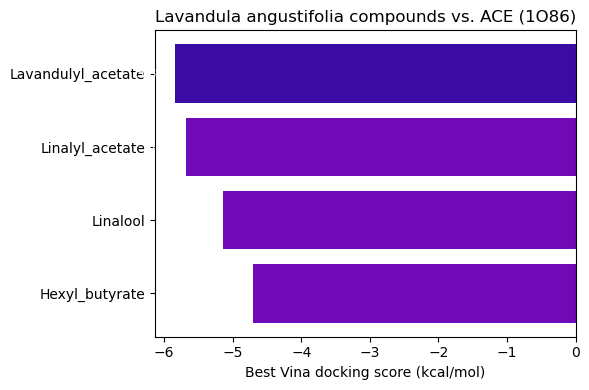

Saved figure: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/figures/lavandula_angustifolia_vs_ACE_scores.png


In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#3a0ca3' if s == docking_df_angustifolia_ACE['Best_Vina_Score_kcal_mol'].min() else '#7209b7'
          for s in docking_df_angustifolia_ACE['Best_Vina_Score_kcal_mol']]
ax.barh(docking_df_angustifolia_ACE['Compound'], docking_df_angustifolia_ACE['Best_Vina_Score_kcal_mol'], color=colors)
ax.set_xlabel('Best Vina docking score (kcal/mol)')
ax.set_title('Lavandula angustifolia compounds vs. ACE (1O86)')
ax.invert_yaxis()
for i, v in enumerate(docking_df_angustifolia_ACE['Best_Vina_Score_kcal_mol']):
    ax.text(v - 0.15, i, f"{v:.2f}", va='center', ha='right', fontsize=9, color='white')
plt.tight_layout()

fig_path_angustifolia_ACE = os.path.join(FIGURES_DIR, 'lavandula_angustifolia_vs_ACE_scores.png')
plt.savefig(fig_path_angustifolia_ACE, dpi=300, bbox_inches='tight')
plt.show()
print("Saved figure:", fig_path_angustifolia_ACE)


### 7.8. ProLif interaction fingerprints -- Lavandula_angustifolia vs ACE (each compound, own cell)

`n_jobs=1` avoids a multiprocessing/pickling crash in this environment;
`to_dataframe()` takes no arguments in ProLif 2.2.1.

In [19]:
prot_fp = mda.Universe("1O86_clean_H_fix.pdb")  # fix_protein() output
prot_fp = plf.Molecule.from_mda(prot_fp)


In [20]:
# ---- ProLif: Linalyl_acetate ----
lig_suppl_Linalyl_acetate = list(plf.sdf_supplier(vina_out_sdf_Linalyl_acetate))
fp_Linalyl_acetate = plf.Fingerprint()
fp_Linalyl_acetate.run_from_iterable(lig_suppl_Linalyl_acetate, prot_fp, n_jobs=1)
results_df_Linalyl_acetate = fp_Linalyl_acetate.to_dataframe()

print("=== Linalyl_acetate ===")
display(results_df_Linalyl_acetate)

net_Linalyl_acetate = fp_Linalyl_acetate.plot_lignetwork(lig_suppl_Linalyl_acetate[0], kind="frame", frame=0, rotation=270)
net_png_Linalyl_acetate = os.path.join(FIGURES_DIR, "Linalyl_acetate_1O86_2Dnetwork.png")
net_Linalyl_acetate.save_png(net_png_Linalyl_acetate)
print("Saved network figure:", net_png_Linalyl_acetate)


  0%|          | 0/10 [00:00<?, ?it/s]

=== Linalyl_acetate ===


ligand            UNL1                                            
protein       VAL380.A   ASP415.A   PHE457.A   TYR520.A   PHE527.A
interaction VdWContact VdWContact VdWContact VdWContact VdWContact
Frame                                                             
0                 True      False       True       True       True
1                False      False      False       True       True
2                False      False       True      False       True
3                 True      False       True       True       True
4                False      False       True       True       True
5                 True      False      False       True       True
6                False      False       True       True       True
7                False       True       True       True       True
8                False      False       True       True      False
9                 True      False      False      False       True

TypeError: LigNetwork.save_png() takes 1 positional argument but 2 were given

In [21]:
# ---- ProLif: Linalool ----
lig_suppl_Linalool = list(plf.sdf_supplier(vina_out_sdf_Linalool))
fp_Linalool = plf.Fingerprint()
fp_Linalool.run_from_iterable(lig_suppl_Linalool, prot_fp, n_jobs=1)
results_df_Linalool = fp_Linalool.to_dataframe()

print("=== Linalool ===")
display(results_df_Linalool)

net_Linalool = fp_Linalool.plot_lignetwork(lig_suppl_Linalool[0], kind="frame", frame=0, rotation=270)
net_png_Linalool = os.path.join(FIGURES_DIR, "Linalool_1O86_2Dnetwork.png")
net_Linalool.save_png(net_png_Linalool)
print("Saved network figure:", net_png_Linalool)


  0%|          | 0/10 [00:00<?, ?it/s]

=== Linalool ===


ligand            UNL1                                                       \
protein       THR282.A   VAL380.A HIS387.A              GLU411.A   ASP415.A   
interaction VdWContact VdWContact  HBDonor VdWContact VdWContact VdWContact   
Frame                                                                         
0                False      False    False      False      False      False   
1                False      False    False      False      False       True   
2                False      False    False      False      False      False   
3                False      False    False      False      False      False   
4                 True      False    False      False      False       True   
5                False      False    False      False      False      False   
6                False      False     True       True       True      False   
7                False       True    False      False      False      False   
8                False      False    False      False      False      False   
9                False       True    False      False      False       True   

ligand                                                   
protein       PHE457.A   TYR520.A   TYR523.A   PHE527.A  
interaction VdWContact VdWContact VdWContact VdWContact  
Frame                                                    
0                 True       True      False       True  
1                 True       True      False       True  
2                 True       True      False       True  
3                 True       True      False       True  
4                False      False      False       True  
5                 True       True      False       True  
6                False      False       True      False  
7                 True       True      False      False  
8                 True       True      False       True  
9                False      False      False      False

TypeError: LigNetwork.save_png() takes 1 positional argument but 2 were given

In [22]:
# ---- ProLif: Hexyl_butyrate ----
lig_suppl_Hexyl_butyrate = list(plf.sdf_supplier(vina_out_sdf_Hexyl_butyrate))
fp_Hexyl_butyrate = plf.Fingerprint()
fp_Hexyl_butyrate.run_from_iterable(lig_suppl_Hexyl_butyrate, prot_fp, n_jobs=1)
results_df_Hexyl_butyrate = fp_Hexyl_butyrate.to_dataframe()

print("=== Hexyl_butyrate ===")
display(results_df_Hexyl_butyrate)

net_Hexyl_butyrate = fp_Hexyl_butyrate.plot_lignetwork(lig_suppl_Hexyl_butyrate[0], kind="frame", frame=0, rotation=270)
net_png_Hexyl_butyrate = os.path.join(FIGURES_DIR, "Hexyl_butyrate_1O86_2Dnetwork.png")
net_Hexyl_butyrate.save_png(net_png_Hexyl_butyrate)
print("Saved network figure:", net_png_Hexyl_butyrate)


  0%|          | 0/10 [00:00<?, ?it/s]

=== Hexyl_butyrate ===


ligand            UNL1                                                         \
protein       VAL380.A   LYS454.A   PHE457.A   LYS511.A   HIS513.A   TYR520.A   
interaction VdWContact VdWContact VdWContact VdWContact VdWContact VdWContact   
Frame                                                                           
0                 True      False       True      False      False      False   
1                 True      False       True       True      False       True   
2                False      False       True      False      False       True   
3                 True      False      False      False      False       True   
4                False       True       True      False      False      False   
5                 True       True       True      False      False      False   
6                False      False       True      False      False      False   
7                 True      False       True       True       True       True   
8                 True      False       True      False      False      False   
9                 True       True       True      False      False      False   

ligand                  
protein       PHE527.A  
interaction VdWContact  
Frame                   
0                 True  
1                 True  
2                False  
3                False  
4                 True  
5                False  
6                False  
7                False  
8                 True  
9                 True

TypeError: LigNetwork.save_png() takes 1 positional argument but 2 were given

In [23]:
# ---- ProLif: Lavandulyl_acetate ----
lig_suppl_Lavandulyl_acetate = list(plf.sdf_supplier(vina_out_sdf_Lavandulyl_acetate))
fp_Lavandulyl_acetate = plf.Fingerprint()
fp_Lavandulyl_acetate.run_from_iterable(lig_suppl_Lavandulyl_acetate, prot_fp, n_jobs=1)
results_df_Lavandulyl_acetate = fp_Lavandulyl_acetate.to_dataframe()

print("=== Lavandulyl_acetate ===")
display(results_df_Lavandulyl_acetate)

net_Lavandulyl_acetate = fp_Lavandulyl_acetate.plot_lignetwork(lig_suppl_Lavandulyl_acetate[0], kind="frame", frame=0, rotation=270)
net_png_Lavandulyl_acetate = os.path.join(FIGURES_DIR, "Lavandulyl_acetate_1O86_2Dnetwork.png")
net_Lavandulyl_acetate.save_png(net_png_Lavandulyl_acetate)
print("Saved network figure:", net_png_Lavandulyl_acetate)


  0%|          | 0/10 [00:00<?, ?it/s]

=== Lavandulyl_acetate ===


ligand            UNL1                                                         \
protein       THR282.A   SER355.A   VAL380.A   LYS454.A   PHE457.A   LYS511.A   
interaction VdWContact VdWContact VdWContact VdWContact VdWContact VdWContact   
Frame                                                                           
0                False      False      False       True       True       True   
1                False      False       True      False       True       True   
2                False      False      False      False       True      False   
3                False      False       True      False       True      False   
4                 True      False      False      False       True      False   
5                False      False       True      False       True      False   
6                False      False      False      False      False       True   
7                False      False       True      False       True      False   
8                 True      False      False      False       True      False   
9                False       True      False      False      False      False   

ligand                                        
protein       PHE512.A   TYR520.A   PHE527.A  
interaction VdWContact VdWContact VdWContact  
Frame                                         
0                False       True       True  
1                False       True       True  
2                False       True       True  
3                False       True      False  
4                False      False       True  
5                False       True       True  
6                False       True      False  
7                False       True       True  
8                False       True      False  
9                 True      False      False

TypeError: LigNetwork.save_png() takes 1 positional argument but 2 were given

### 7.9. Figure -- best-scoring compound vs. the real native ligand (lisinopril)

In [24]:
best_row_angustifolia_ACE = docking_df_angustifolia_ACE.iloc[0]
best_compound_angustifolia_ACE = best_row_angustifolia_ACE['Compound']
print("Best-scoring compound:", best_compound_angustifolia_ACE, "|", best_row_angustifolia_ACE['Best_Vina_Score_kcal_mol'], "kcal/mol")

best_sdf_angustifolia_ACE = {
    "Linalyl_acetate": vina_out_sdf_Linalyl_acetate,
    "Linalool": vina_out_sdf_Linalool,
    "Hexyl_butyrate": vina_out_sdf_Hexyl_butyrate,
    "Lavandulyl_acetate": vina_out_sdf_Lavandulyl_acetate,
}[best_compound_angustifolia_ACE]

view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open(RECEPTOR_PDB,'r').read(), format='pdb')
Prot = view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW, {'opacity':0.6,'color':'white'})

view.addModel(open(NATIVE_LIG,'r').read(), format='mol2')
ref_m = view.getModel()
ref_m.setStyle({}, {'stick':{'colorscheme':'magentaCarbon','radius':0.2}})

results_ang_ACE = Chem.SDMolSupplier(best_sdf_angustifolia_ACE)
p_ang_ACE = Chem.MolToMolBlock(results_ang_ACE[0], False)
print('Reference (lisinopril): Magenta | Best compound pose: Cyan')
print('Pose: {} | Score: {}'.format(results_ang_ACE[0].GetProp('Pose'), results_ang_ACE[0].GetProp('Score')))

view.addModel(p_ang_ACE, 'mol')
x = view.getModel()
x.setStyle({}, {'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()


Best-scoring compound: Lavandulyl_acetate | -5.837 kcal/mol
Reference (lisinopril): Magenta | Best compound pose: Cyan
Pose: 1 | Score: -5.837


3Dmol.js failed to load for some reason. Please check your browser console for error messages.